# 5. A tiny twin: the cancer model's shape, on a laptop

The talk's second case is a tumour organoid under CAR T-cell therapy: thousands of cells, each an agent, on an oxygen field, in C++ on BioDynaMo. That stack does not install at home. This notebook keeps its *shape* in sixty lines of C++ (`kernel/twin.h`): cells on a line that grow by the header of notebook 1 at a rate set by the oxygen they get; oxygen that diffuses in from the edges and is consumed by the cells; two knobs the real model also has, the consumption rate and the edge oxygen.

The three verbs again. **Call it**: step the model from Python. **Compose it**: a Python function is handed to C++ and runs inside the loop, seeding a second colony mid-run. **Transform it**: the smooth part (oxygen) is restated as one function; Clad's gradient of it (`kernel/twin_clad.h`) calibrates both knobs from a few measurements, with the cells frozen, exactly as the talk calibrates the real model.

In [1]:
import cppjit, numpy as np, matplotlib.pyplot as plt, time
cppjit.add_include_path("kernel"); cppjit.include("twin.h")
from kernel import derivatives; derivatives.load("twin")    # Clad writes the oxygen gradient in its two knobs, in the session
print(open("kernel/twin.h").read().split("struct Twin")[0][-600:])

t a rate
// set by the oxygen there and spreads to its neighbours, so the colony's front advances. Oxygen diffuses along the line from both edges, which are held at o_edge (the medium),
// and is consumed by the cells. Two knobs the real model also has: the consumption rate `cons` and the edge
// oxygen `o_edge`. The smooth part (oxygen) is restated below as one function the compiler can differentiate,
// exactly as the talk restates the real model's oxygen update.
#pragma once
#include <cmath>
#include <functional>
#include <vector>
#include "logistic_step.h"

constexpr int kMaxSites = 256;




[clad] oxygen_after_grad_2_3: generated by the Clad inside this kernel


## Call it: run the twin and look at it

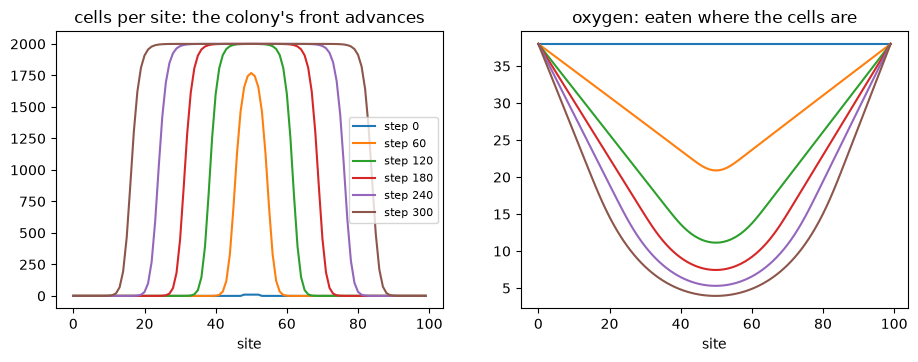

134525 cells after 300 steps; mean oxygen at the cells 8.25 of 38 at the edges


In [2]:
def profiles(t): return np.asarray(t.c.data()).copy(), np.asarray(t.o.data()).copy()    # zero-copy views, copied for keeping
twin = cppjit.gbl.Twin(100, 38.0)                 # 100 sites, 38 units of oxygen at both edges; a 5-site colony in the middle
snap = {}
for step in range(0, 301):
    if step in (0, 60, 120, 180, 240, 300): snap[step] = profiles(twin)
    if step < 300: twin.step()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s, (c, o) in snap.items(): ax[0].plot(c, label=f"step {s}"); ax[1].plot(o, label=f"step {s}")
ax[0].set_title("cells per site: the colony's front advances"); ax[1].set_title("oxygen: eaten where the cells are"); ax[0].legend(fontsize=8); ax[0].set_xlabel("site"); ax[1].set_xlabel("site"); plt.show()
print(f"{twin.total_cells():.0f} cells after 300 steps; mean oxygen at the cells {twin.mean_oxygen_at_cells():.2f} of 38 at the edges")

## Compose it: a Python function inside the C++ loop

`run(twin, steps, hook)` takes a `std::function`. A Python function is a valid one. The scheduler calls it before every step; at step 150 it seeds a second colony at the far end. Nothing in the C++ knows Python exists.

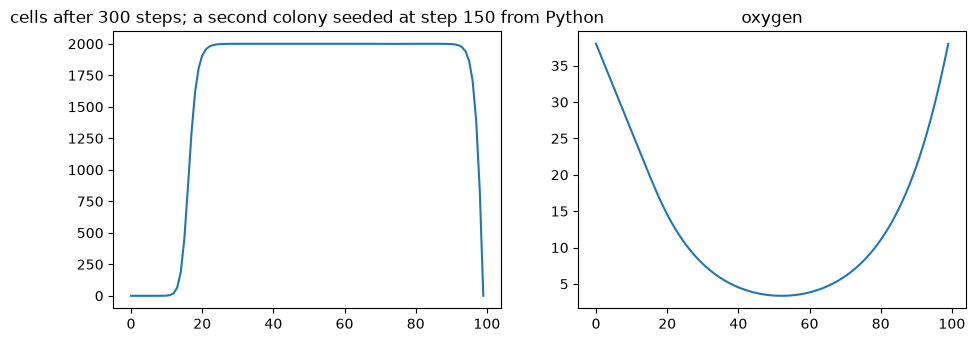

total cells at steps 0, 50, ...: [(0, 50), (50, 10201), (100, 36420), (150, 59983), (200, 92569), (250, 136090)]


In [3]:
twin2 = cppjit.gbl.Twin(100, 38.0)
log = []
def hook(step, t):
    if step == 150:
        c = np.asarray(t.c.data()); c[80:85] = 10.0                 # the Python-side intervention, through the shared memory
    if step % 50 == 0: log.append((step, round(t.total_cells())))
cppjit.gbl.run(twin2, 300, hook)                                   # C++ loop, Python hook inside it
c, o = profiles(twin2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); ax[0].plot(c); ax[0].set_title("cells after 300 steps; a second colony seeded at step 150 from Python"); ax[1].plot(o); ax[1].set_title("oxygen"); plt.show()
print("total cells at steps 0, 50, ...:", log)

## Transform it: calibrate the two oxygen knobs from a few measurements

Suppose the twin were a real organoid and we could only measure the mean oxygen at the cells at five times, with the cell profiles known (from images). The oxygen sub-model is smooth, so it has a derivative. `oxygen_after(cells, ...)` restates it: from a uniform field, run the oxygen substeps over the *frozen* cells, return the mean. Clad wrote its gradient with respect to the two knobs. Levenberg-Marquardt on that gradient recovers both knobs from a 20 % wrong start in a handful of evaluations, with no simulation in the loop. (The cells are frozen as they were when the oxygen was computed: in `Twin::step` the oxygen substeps come first.)

In [4]:
# the "measurements": from a run at a hidden truth, read at five checkpoints
TRUE = dict(cons=1.2e-5, o_edge=38.0)
ref = cppjit.gbl.Twin(100, TRUE["o_edge"]); ref.cons = TRUE["cons"]; checkpoints = (60, 120, 180, 240, 300); cells_at, obs = [], []
for step in range(1, 301):
    before = np.asarray(ref.c.data()).copy()     # the cells the oxygen of this step is computed on
    ref.step()
    if step in checkpoints: cells_at.append(before); obs.append(ref.mean_oxygen_at_cells())
obs = np.array(obs); print("measured mean oxygen at the cells:", np.round(obs, 3))
g = cppjit.gbl.clad_generated; n = ref.n; D, dto, ITERS = ref.D, ref.dto, 8000   # 8000 substeps: the steady state for these cells
def resid(x):                               # x = (cons in units of 1e-5, o_edge): the two knobs, scaled to order one
    return np.array([cppjit.gbl.oxygen_after(c, n, x[0] * 1e-5, x[1], D, dto, ITERS) for c in cells_at]) - obs
def jac(x):                                 # Clad's gradient of oxygen_after with respect to the two knobs, per checkpoint
    J = np.zeros((len(obs), 2))
    for i, c in enumerate(cells_at):
        dc, doe = np.zeros(1), np.zeros(1); g.oxygen_after_grad_2_3(c, n, x[0] * 1e-5, x[1], D, dto, ITERS, dc, doe); J[i] = (dc[0] * 1e-5, doe[0])
    return J
from scipy.optimize import least_squares
x0 = np.array([TRUE["cons"] * 1e5 * 1.2, TRUE["o_edge"] * 0.8]); print(f"start: cons {x0[0]*1e-5:.2e}, o_edge {x0[1]:.2f}   (truth {TRUE['cons']:.2e}, {TRUE['o_edge']:.2f})")
t0 = time.time(); fit = least_squares(resid, x0, jac=jac, method="lm", xtol=1e-12, ftol=1e-12)
print(f"fit:   cons {fit.x[0]*1e-5:.4e}, o_edge {fit.x[1]:.4f}   in {fit.nfev} evaluations of the oxygen model, {time.time() - t0:.1f} s; rms misfit {np.sqrt(np.mean(fit.fun**2)):.1e}")
print(f"relative error: cons {abs(fit.x[0]*1e-5 / TRUE['cons'] - 1):.1e}, o_edge {abs(fit.x[1] / TRUE['o_edge'] - 1):.1e}")

measured mean oxygen at the cells: [19.607 10.944  8.395  7.367  7.216]


start: cons 1.44e-05, o_edge 30.40   (truth 1.20e-05, 38.00)


fit:   cons 1.1961e-05, o_edge 38.0552   in 7 evaluations of the oxygen model, 2.6 s; rms misfit 8.5e-03
relative error: cons 3.2e-03, o_edge 1.5e-03


## Does the frozen answer hold in the live model?

Put the fitted knobs into a fresh twin and run it; compare the live mean oxygen with the measurements.

In [5]:
live = cppjit.gbl.Twin(100, fit.x[1]); live.cons = fit.x[0] * 1e-5; got = []
for step in range(1, 301):
    live.step()
    if step in checkpoints: got.append(live.mean_oxygen_at_cells())
print("measured  :", np.round(obs, 4)); print("live refit:", np.round(got, 4)); print("max abs difference:", f"{np.abs(np.array(got) - obs).max():.1e}")

measured  : [19.6069 10.9438  8.3948  7.3671  7.2164]
live refit: [19.6611 10.982   8.426   7.3955  7.2446]
max abs difference: 5.4e-02


## What this stands in for

| here | the talk's model |
|---|---|
| 100 sites on a line, cells as counts | 3,957 to 24,000 agents in 3-D on BioDynaMo |
| oxygen: explicit diffusion, 60 lines | oxygen and a signal field, implicit solver on a 50³ grid |
| growth: the header of notebook 1, oxygen-dependent | division, death and killing as per-cell rules |
| the hook seeds a colony | a Python class scheduled as a BioDynaMo operation seeds a second organoid |
| two knobs fitted on frozen cells in a handful of evaluations | the same, on the real model, in 5 steps of a minute |

What does not carry over: the random parts. Cell division, death and killing in the real model are dice rolls; no compiler differentiates those, and the talk measures their response with paired runs instead.

## Play with it

- Make the line longer or the colony bigger; find the consumption at which the core goes hypoxic.
- Measure only at one checkpoint. Can two knobs be recovered from one number? (The Jacobian tells you: look at its rank.)
- Give the hook a schedule: a "dose" that removes cells at a site, every 100 steps.